# Deteção de Faces: WIDER FACE + Haar Cascade
## 1. Imports e Configurações

In [1]:
import json
import os
import random
import time
from concurrent.futures import ThreadPoolExecutor, as_completed
from pathlib import Path

import cv2
import matplotlib.patches as patches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from PIL import Image
from tqdm.notebook import tqdm


In [2]:
# Paths
DATASET_PATH = Path("../dataset")
WIDER_TRAIN_DIR = DATASET_PATH / "WIDER_train/images"
WIDER_VAL_DIR = DATASET_PATH / "WIDER_val/images"
WIDER_TEST_DIR = DATASET_PATH / "WIDER_test/images"

WIDER_ANNO = DATASET_PATH / "wider_face_split/wider_face_train_bbx_gt.txt"
WIDER_VAL_ANNO = DATASET_PATH / "wider_face_split/wider_face_val_bbx_gt.txt"

OUTPUT_FILE = "haar_evaluation_results.csv"
METRICS_FILE = "haar_evaluation_metrics.json"

EXT_DATASET_PATH = DATASET_PATH / "test_dataset"
EXT_IMAGES_DIR = EXT_DATASET_PATH / "images"
EXT_LABELS_DIR = EXT_DATASET_PATH / "labels"

# Seed para reprodutibilidade
SEED = 2
random.seed(SEED)
np.random.seed(SEED)

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["figure.dpi"] = 100

## 2. Carregamento do Dataset WIDER FACE

In [3]:
def load_wider_annotations(anno_path: Path) -> list[dict]:
    """
    Lê o ficheiro de anotações do WIDER FACE e devolve uma lista de registos.
    Cada registo contém:
      - img_rel_path: caminho relativo da imagem
      - boxes: lista de bounding boxes válidas
      - num_faces: número de rostos válidos
      - min_dim: dimensão mínima (min(w,h)) entre todos os rostos
      - max_occlusion: nível máximo de oclusão (0, 1 ou 2)
      - max_blur: nível máximo de blur (0, 1 ou 2)
    """
    dataset_records = []

    with open(anno_path, "r") as f:
        lines = [line.strip() for line in f if line.strip()]

    i = 0
    while i < len(lines):
        img_rel_path = lines[i]
        i += 1

        if not img_rel_path.endswith(".jpg"):
            continue

        num_faces = int(lines[i])
        i += 1

        faces_in_image = []
        dims = []
        occlusions = []
        blurs = []

        if num_faces == 0:
            if i < len(lines) and not lines[i].endswith(".jpg"):
                i += 1
        else:
            for _ in range(num_faces):
                parts = list(map(int, lines[i].split()))
                i += 1

                if len(parts) >= 9:
                    x, y, w, h = parts[:4]
                    invalid = parts[7]
                    occlusion = parts[8]
                    blur = parts[4] if len(parts) >= 5 else 0

                    if invalid == 0 and w > 0 and h > 0:
                        box_dict = {
                            "x": x, "y": y, "w": w, "h": h,
                            "occlusion": occlusion, "blur": blur,
                            "area": w * h,
                        }
                        faces_in_image.append(box_dict)
                        dims.append(min(w, h))
                        occlusions.append(occlusion)
                        blurs.append(blur)

        dataset_records.append({
            "img_rel_path": img_rel_path,
            "boxes": faces_in_image,
            "num_faces": len(faces_in_image),
            "min_dim": min(dims) if dims else 0,
            "max_occlusion": max(occlusions) if occlusions else 0,
            "max_blur": max(blurs) if blurs else 0,
        })

    return dataset_records

def load_external_yolo_dataset(labels_dir: Path, images_dir: Path) -> list[dict]:
    dataset_records = []
    txt_files = list(labels_dir.rglob("*.txt"))
    
    for txt_path in txt_files:
        rel_path_from_labels = txt_path.relative_to(labels_dir)
        img_stem = rel_path_from_labels.stem
        
        img_path = images_dir / rel_path_from_labels.parent / f"{img_stem}.jpg"
        if not img_path.exists():
            img_path = images_dir / rel_path_from_labels.parent / f"{img_stem}.png"
            
        if not img_path.exists():
            continue
            
        with Image.open(img_path) as img:
            img_w, img_h = img.size
            
        faces_in_image = []
        dims = []
        
        with open(txt_path, "r") as f:
            lines = f.readlines()
            
        for line in lines:
            parts = line.strip().split()
            if len(parts) >= 5 and int(parts[0]) == 0:
                w_abs = int(float(parts[3]) * img_w)
                h_abs = int(float(parts[4]) * img_h)
                x_abs = max(0, int((float(parts[1]) * img_w) - (w_abs / 2)))
                y_abs = max(0, int((float(parts[2]) * img_h) - (h_abs / 2)))
                w_abs = min(img_w - x_abs, w_abs)
                h_abs = min(img_h - y_abs, h_abs)
                
                if w_abs > 0 and h_abs > 0:
                    box_dict = {
                        "x": x_abs, "y": y_abs, "w": w_abs, "h": h_abs,
                        "occlusion": 0, "blur": 0, "area": w_abs * h_abs
                    }
                    faces_in_image.append(box_dict)
                    dims.append(min(w_abs, h_abs))
        
        img_rel_path = str(rel_path_from_labels.parent / img_path.name)
        
        dataset_records.append({
            "img_rel_path": img_rel_path,
            "boxes": faces_in_image,
            "num_faces": len(faces_in_image),
            "min_dim": min(dims) if dims else 0,
            "max_occlusion": 0,
            "max_blur": 0
        })
        
    return dataset_records

In [4]:
dataset_records = load_wider_annotations(WIDER_ANNO)
val_records = load_wider_annotations(WIDER_VAL_ANNO)
test_records = load_external_yolo_dataset(EXT_LABELS_DIR, EXT_IMAGES_DIR)

## 5. Haar Cascade - Deteção de Faces

Imagem: 227ee6f582274966.jpg
Tempo de inferência: 0.2542 segundos
Confiança: [5.048822128330357]
Rostos detetados: 1


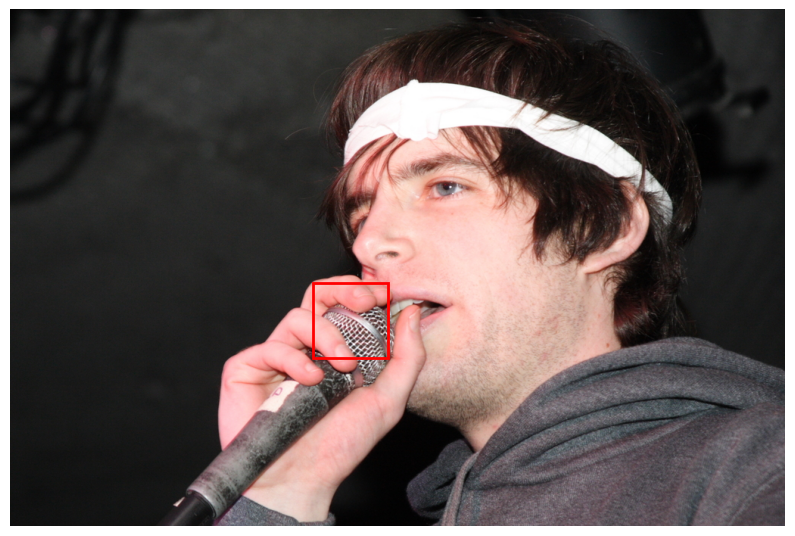

In [5]:
# Carregar o classificador pré-treinado
face_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
)


def detect_faces_haar(img_path: Path, scale_factor=1.1, min_neighbors=4, min_size=(20, 20)):
    """Lê uma imagem, corre o Haar Cascade, aplica NMS e devolve também as confianças."""
    img = cv2.imread(str(img_path))
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    start_time = time.perf_counter()
    
    # Usar detectMultiScale3 para obter os pesos (níveis de confiança)
    faces, rejectLevels, levelWeights = face_cascade.detectMultiScale3(
        gray, scaleFactor=scale_factor, minNeighbors=min_neighbors, 
        minSize=min_size, outputRejectLevels=True
    )
    
    if len(faces) > 0:
        boxes_nms = [[x, y, x + w, y + h] for (x, y, w, h) in faces]
        scores = levelWeights.flatten().tolist()
        
        # NMS real baseado nas confianças do modelo
        indices = cv2.dnn.NMSBoxes(boxes_nms, scores, score_threshold=0.0, nms_threshold=0.3)
        
        if len(indices) > 0:
            faces = np.array([faces[i] for i in indices])
            final_scores = [scores[i] for i in indices]
        else:
            faces = np.array([])
            final_scores = []
    else:
        faces = np.array([])
        final_scores = []

    inference_time = time.perf_counter() - start_time
    # Devolvemos as confianças como 3º argumento
    return img, faces, final_scores, inference_time

# Teste rápido numa imagem
img_teste = random.choice(list(EXT_IMAGES_DIR.rglob("*.jpg")))
img, faces_detectadas, score, tempo = detect_faces_haar(img_teste)

print(f"Imagem: {img_teste.name}")
print(f"Tempo de inferência: {tempo:.4f} segundos")
print(f"Confiança: {score}" )
print(f"Rostos detetados: {len(faces_detectadas)}")

img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img_rgb)
for (x, y, w, h) in faces_detectadas:
    rect = patches.Rectangle((x, y), w, h, linewidth=2, edgecolor="red", facecolor="none")
    ax.add_patch(rect)
plt.axis("off")
plt.show()

## 6. Avaliação com IoU

Para avaliar a qualidade das deteções, calculamos o **Intersection over Union (IoU)** entre as bounding boxes previstas pelo Haar Cascade e as ground truth do WIDER FACE.

In [6]:
def calc_iou(boxA, boxB):
    """
    Calcula o IoU entre duas caixas.
    Formato esperado: (x, y, w, h)
    """
    xA = max(boxA[0], boxB[0])
    yA = max(boxA[1], boxB[1])
    xB = min(boxA[0] + boxA[2], boxB[0] + boxB[2])
    yB = min(boxA[1] + boxA[3], boxB[1] + boxB[3])

    interArea = max(0, xB - xA) * max(0, yB - yA)
    if interArea == 0:
        return 0.0

    boxAArea = boxA[2] * boxA[3]
    boxBArea = boxB[2] * boxB[3]

    iou = interArea / float(boxAArea + boxBArea - interArea)
    return iou


def get_image_scores(output_boxes, img_faces, min_iou=0.1):
    """
    Devolve um array de scores (IoU) para cada cara real, garantindo que
    nenhuma caixa detetada é usada duas vezes e nenhuma cara recebe duas caixas.
    """
    scores = [0.0] * len(img_faces)

    if len(img_faces) == 0 or len(output_boxes) == 0:
        return scores

    # 1. Calcular todos os cruzamentos possíveis
    todas_as_combinacoes = []
    for i, out_box in enumerate(output_boxes):
        for j, gt_face in enumerate(img_faces):
            iou = calc_iou(out_box, gt_face)
            if iou >= min_iou:
                todas_as_combinacoes.append((iou, i, j))

    # 2. Ordenar do IoU mais alto para o mais baixo (algoritmo guloso)
    todas_as_combinacoes.sort(key=lambda x: x[0], reverse=True)

    # 3. Conjuntos para ir "riscando" o que já foi atribuído
    outputs_usados = set()
    caras_reais_usadas = set()

    # 4. Fazer o emparelhamento oficial
    for iou, out_idx, gt_idx in todas_as_combinacoes:
        if out_idx not in outputs_usados and gt_idx not in caras_reais_usadas:
            scores[gt_idx] = iou
            outputs_usados.add(out_idx)
            caras_reais_usadas.add(gt_idx)

    return scores

## 7. Otimização de Hiperparâmetros

In [ ]:
def evaluate_single_config(scale, neighbors, min_sz, records, images_dir, iou_threshold):
    """Avalia uma única combinação criando uma instância própria do classificador por thread."""
    
    # Criar uma instância própria do classificador dentro desta thread (evita conflitos em C++)
    local_cascade = cv2.CascadeClassifier(
        cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
    )
    
    total_gt = 0
    total_tp = 0
    total_fp = 0
    total_fn = 0
    total_time = 0.0
    valid_images = 0
    
    for record in records:
        img_path = images_dir / record["img_rel_path"]
        if not img_path.exists():
            continue
        
        img = cv2.imread(str(img_path))
        if img is None:
            continue
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        
        start_time = time.perf_counter()
        faces = local_cascade.detectMultiScale(
            gray, scaleFactor=scale, minNeighbors=neighbors, minSize=min_sz
        )
        inference_time = time.perf_counter() - start_time
        
        if len(faces) > 0:
            boxes_nms = [[x, y, x + w, y + h] for (x, y, w, h) in faces]
            scores = [1.0] * len(faces)
            indices = cv2.dnn.NMSBoxes(boxes_nms, scores, score_threshold=0.5, nms_threshold=0.3)
            if len(indices) > 0:
                faces = np.array([faces[i] for i in indices])
            else:
                faces = np.array([])
                
        total_time += inference_time
        valid_images += 1
        
        gt_boxes = [(b["x"], b["y"], b["w"], b["h"]) for b in record["boxes"]]
        pred_boxes = [(int(x), int(y), int(w), int(h)) for (x, y, w, h) in faces]
        
        ious = get_image_scores(pred_boxes, gt_boxes, min_iou=0.0)
        
        n_gt = len(gt_boxes)
        n_pred = len(pred_boxes)
        n_tp = sum(1 for iou in ious if iou >= iou_threshold)
        n_fp = n_pred - n_tp
        n_fn = n_gt - n_tp
        
        total_gt += n_gt
        total_tp += n_tp
        total_fp += n_fp
        total_fn += n_fn
    
    precision = total_tp / (total_tp + total_fp) if (total_tp + total_fp) > 0 else 0.0
    recall = total_tp / (total_tp + total_fn) if (total_tp + total_fn) > 0 else 0.0
    f1 = (2 * precision * recall) / (precision + recall) if (precision + recall) > 0 else 0.0
    
    avg_time = total_time / valid_images if valid_images > 0 else 0.0
    
    return {
        'scaleFactor': scale,
        'minNeighbors': neighbors,
        'minSize': min_sz,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'avg_time': avg_time
    }

def hyperparameter_search_parallel(records, images_dir, iou_threshold=0.5, max_workers=6):
    """
    Testa o Grid Search em paralelo usando múltiplas threads com uma única barra de progresso limpa.
    """
    param_grid = {
        'scaleFactor': [1.05, 1.0, 0.95],
        'minNeighbors': [3, 4, 5, 6],
        'minSize': [(15, 15), (20, 20), (25, 25)]
    }
    
    tasks = []
    for scale in param_grid['scaleFactor']:
        for neighbors in param_grid['minNeighbors']:
            for min_sz in param_grid['minSize']:
                tasks.append((scale, neighbors, min_sz))
                
    results = []
    print(f"🚀 A executar {len(tasks)} combinações de hiperparâmetros com {max_workers} threads...")
    
    with ThreadPoolExecutor(max_workers=max_workers) as executor:
        # Submeter todas as tarefas de uma vez
        futures = {
            executor.submit(evaluate_single_config, scale, neighbors, min_sz, records, images_dir, iou_threshold): (scale, neighbors, min_sz)
            for scale, neighbors, min_sz in tasks
        }
        
        for future in tqdm(as_completed(futures), total=len(tasks), desc="Grid Search"):
            results.append(future.result())
            
    return pd.DataFrame(results)

In [9]:
print(f"A iniciar grid search de hiperparâmetros ({len(val_records)} imagens)...")
df_hyperparams = hyperparameter_search_parallel(
    val_records[:500],
    images_dir=WIDER_VAL_DIR,
    iou_threshold=0.5,
    max_workers=6
)

best_params = df_hyperparams.loc[df_hyperparams['f1'].idxmax()]
BEST_SCALE = best_params['scaleFactor']
BEST_NEIGHBORS = best_params['minNeighbors']
BEST_MINSIZE = best_params['minSize']

print("\n" + "="*70)
print("RESULTADOS DO GRID SEARCH")
print("="*70)
print(df_hyperparams.sort_values('f1', ascending=False).to_string(index=False))

# Melhor combinação por F1-Score
print("\n" + "="*70)
print("MELHORES HIPERPARÂMETROS (por F1-Score)")
print("="*70)
print(f"scaleFactor:  {best_params['scaleFactor']}")
print(f"minNeighbors: {best_params['minNeighbors']}")
print(f"minSize:      {best_params['minSize']}")
print(f"F1-Score:     {best_params['f1']:.4f}")
print(f"Precision:    {best_params['precision']:.4f}")
print(f"Recall:       {best_params['recall']:.4f}")
print(f"Tempo médio:  {best_params['avg_time']*1000:.2f} ms")

A iniciar grid search de hiperparâmetros (3226 imagens)...
🚀 A executar 36 combinações de hiperparâmetros com 6 threads...


Grid Search:   0%|          | 0/36 [00:00<?, ?it/s]


RESULTADOS DO GRID SEARCH
 scaleFactor  minNeighbors  minSize  precision   recall       f1  avg_time
        1.05             4 (15, 15)   0.476584 0.104301 0.171146  1.106752
        1.05             6 (15, 15)   0.577571 0.099879 0.170308  0.998531
        1.05             6 (20, 20)   0.576744 0.099678 0.169979  0.968877
        1.05             4 (20, 20)   0.473975 0.103396 0.169760  0.999932
        1.05             5 (15, 15)   0.530407 0.100784 0.169383  0.943837
        1.05             5 (20, 20)   0.529008 0.100784 0.169311  1.077709
        1.10             3 (20, 20)   0.572510 0.098774 0.168481  0.529150
        1.10             3 (15, 15)   0.571928 0.098674 0.168309  0.524145
        1.05             3 (15, 15)   0.410980 0.105305 0.167653  0.959401
        1.05             6 (25, 25)   0.578979 0.097970 0.167583  1.075756
        1.05             5 (25, 25)   0.532075 0.099176 0.167189  1.040398
        1.10             4 (20, 20)   0.653635 0.095760 0.167046  0.46842

## 7. Avaliação em Larga Escala

Vamos avaliar o Haar Cascade numa amostra de imagens do WIDER FACE, calculando métricas como:
- **IoU médio** por imagem
- **Tempo de inferência** médio
- **Precisão** e **Recall** com um limiar de IoU

In [30]:
def evaluate_on_sample(records: list[dict], images_dir, n_samples: int = 500, iou_threshold: float = 0.5):
    sample = random.sample(records, min(n_samples, len(records)))
    
    results = []
    total_time = 0.0
    total_gt = 0
    total_tp = 0
    total_fp = 0
    total_fn = 0
    
    for record in tqdm(sample, desc="A processar imagens"):
        img_path = images_dir / record["img_rel_path"]
        if not img_path.exists():
            continue
        
        # AQUI: Adicionamos o "confidences" para receber os pesos do modelo
        _, faces_detected, confidences, inference_time = detect_faces_haar(
            img_path,
            scale_factor=BEST_SCALE,
            min_neighbors=BEST_NEIGHBORS,
            min_size=BEST_MINSIZE
        )

        total_time += inference_time
        
        gt_boxes = [(b["x"], b["y"], b["w"], b["h"]) for b in record["boxes"]]
        pred_boxes = [(int(x), int(y), int(w), int(h)) for (x, y, w, h) in faces_detected]
        
        ious = get_image_scores(pred_boxes, gt_boxes, min_iou=0.0)
        
        n_gt = len(gt_boxes)
        n_pred = len(pred_boxes)
        n_tp = sum(1 for iou in ious if iou >= iou_threshold)
        n_fp = n_pred - n_tp
        n_fn = n_gt - n_tp
        
        total_gt += n_gt
        total_tp += n_tp
        total_fp += n_fp
        total_fn += n_fn
        ious_com_fp = list(ious) + [0.0] * n_fp
        
        results.append({
            "img_rel_path": record["img_rel_path"],
            "n_gt": n_gt,
            "n_pred": n_pred,
            "n_tp": n_tp,
            "n_fp": n_fp,
            "n_fn": n_fn,
            "mean_iou": np.mean(ious) if ious else 0.0,
            "inference_time": inference_time,
            "num_faces": record["num_faces"],
            "min_dim": record["min_dim"],
            "max_occlusion": record["max_occlusion"],
            "max_blur": record["max_blur"],
            "confidences": confidences,
            "matched_ious": ious_com_fp 
        })
    
    df_results = pd.DataFrame(results)
    
    precision = total_tp / (total_tp + total_fp) if (total_tp + total_fp) > 0 else 0.0
    recall = total_tp / (total_tp + total_fn) if (total_tp + total_fn) > 0 else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0
    
    metrics = {
        "n_images": len(df_results),
        "total_gt": total_gt,
        "total_pred": total_tp + total_fp,
        "total_tp": total_tp,
        "total_fp": total_fp,
        "total_fn": total_fn,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "mean_iou": df_results["mean_iou"].mean(),
        "mean_inference_time": total_time / len(df_results) if len(df_results) > 0 else 0.0,
    }
    
    return df_results, metrics

In [36]:
BEST_SCALE = 1.05
BEST_NEIGHBORS = 5
BEST_MINSIZE = (20,20)
df_results, metrics = evaluate_on_sample(test_records, images_dir=EXT_IMAGES_DIR, n_samples=len(test_records), iou_threshold=0.5)

print("=" * 60)
print("MÉTRICAS GLOBAIS DO HAAR CASCADE")
print("=" * 60)
for k, v in metrics.items():
    if isinstance(v, float):
        print(f"{k:.<30} {v:.4f}")
    else:
        print(f"{k:.<30} {v}")

df_results.to_csv(OUTPUT_FILE, index=False)
print(f"✅ Resultados guardados em: {OUTPUT_FILE}")

with open(METRICS_FILE, 'w') as f:
    json.dump(metrics, f, indent=2)
print(f"✅ Métricas globais guardadas em: {METRICS_FILE}")

A processar imagens:   0%|          | 0/16733 [00:00<?, ?it/s]

MÉTRICAS GLOBAIS DO HAAR CASCADE
n_images...................... 16733
total_gt...................... 51831
total_pred.................... 40639
total_tp...................... 18920
total_fp...................... 21719
total_fn...................... 32911
precision..................... 0.4656
recall........................ 0.3650
f1............................ 0.4092
mean_iou...................... 0.3446
mean_inference_time........... 0.1887
✅ Resultados guardados em: haar_evaluation_results.csv
✅ Métricas globais guardadas em: haar_evaluation_metrics.json


In [37]:
def load_results(path="haar_evaluation_results.csv"):
    path = Path(path) 
    if not path.exists():
        raise FileNotFoundError(f"Ficheiro não encontrado: {path}")

    df = pd.read_csv(path)

    print(f"✅ Resultados carregados de: {path}")
    return df

def load_metrics(path="haar_evaluation_metrics.json"):
    path = Path(path) 
    if not path.exists():
        raise FileNotFoundError(f"Ficheiro não encontrado: {path}")
    
    with open(path, "r") as f:
        metrics = json.load(f)
    
    print(f"✅ Métricas carregadas de: {path}")
    for k, v in metrics.items():
        if isinstance(v, float):
            print(f"   {k:.<30} {v:.4f}")
        else:
            print(f"   {k:.<30} {v}")
    
    return metrics

## 8. Análise por Grau de Dificuldade

C:\Users\User\AppData\Local\Temp\ipykernel_17764\1238611170.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_results, x="size_bucket", y="mean_iou", ax=axes[0], palette="Set2")
C:\Users\User\AppData\Local\Temp\ipykernel_17764\1238611170.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_results, x="crowd_bucket", y="mean_iou", ax=axes[1], palette="Set3")


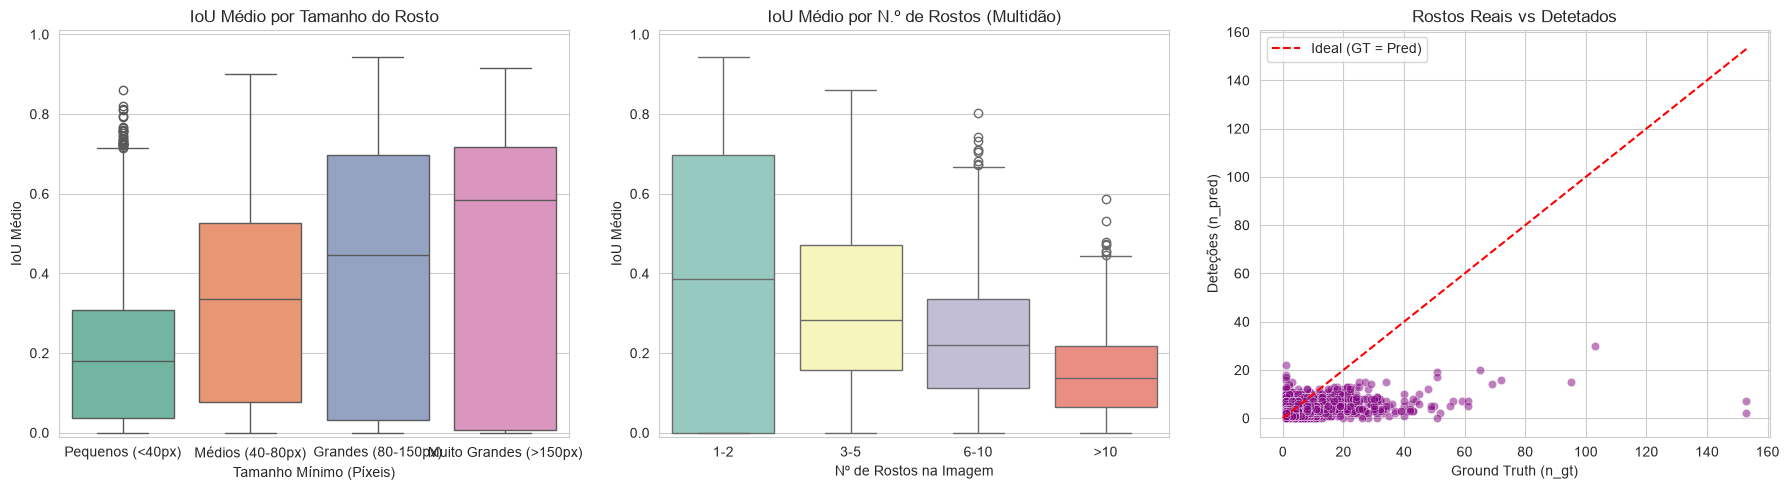

In [38]:
BEST_SCALE = 1.05
BEST_NEIGHBORS = 5
BEST_MINSIZE = (20,20)
if "df_results" not in globals():
    df_results = load_results(OUTPUT_FILE)

if "metrics" not in globals():
    metrics = load_metrics(METRICS_FILE)

# 1. Criar novas categorias baseadas nas métricas intrínsecas que possuímos
# Agrupar pelo tamanho mínimo do rosto na imagem
df_results["size_bucket"] = pd.cut(
    df_results["min_dim"],
    bins=[0, 40, 80, 150, float('inf')],
    labels=["Pequenos (<40px)", "Médios (40-80px)", "Grandes (80-150px)", "Muito Grandes (>150px)"]
)

# Agrupar pela quantidade de rostos na imagem
df_results["crowd_bucket"] = pd.cut(
    df_results["n_gt"],
    bins=[0, 2, 5, 10, float('inf')],
    labels=["1-2", "3-5", "6-10", ">10"]
)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Gráfico 1: IoU médio por Tamanho do Rosto
sns.boxplot(data=df_results, x="size_bucket", y="mean_iou", ax=axes[0], palette="Set2")
axes[0].set_title("IoU Médio por Tamanho do Rosto")
axes[0].set_ylabel("IoU Médio")
axes[0].set_xlabel("Tamanho Mínimo (Píxeis)")
axes[0].set_ylim(-0.01, 1.01)

# Gráfico 2: IoU médio por Quantidade de Rostos
sns.boxplot(data=df_results, x="crowd_bucket", y="mean_iou", ax=axes[1], palette="Set3")
axes[1].set_title("IoU Médio por N.º de Rostos (Multidão)")
axes[1].set_ylabel("IoU Médio")
axes[1].set_xlabel("Nº de Rostos na Imagem")
axes[1].set_ylim(-0.01, 1.01)

# Gráfico 3: Ground Truth vs Deteções (Dispersão)
sns.scatterplot(data=df_results, x="n_gt", y="n_pred", alpha=0.5, ax=axes[2], color="purple")
# Adicionar uma linha de referência y=x (Deteção Perfeita)
max_val = max(df_results["n_gt"].max(), df_results["n_pred"].max())
axes[2].plot([0, max_val], [0, max_val], color='red', linestyle='--', label='Ideal (GT = Pred)')
axes[2].set_title("Rostos Reais vs Detetados")
axes[2].set_xlabel("Ground Truth (n_gt)")
axes[2].set_ylabel("Deteções (n_pred)")
axes[2].legend()

plt.tight_layout()
plt.show()

In [39]:
print("=" * 70)
print("MÉTRICAS POR TAMANHO MÍNIMO DO ROSTO")
print("=" * 70)

# Garantir que os buckets existem (caso não tenhas corrido o bloco anterior)
if "size_bucket" not in df_results.columns:
    df_results["size_bucket"] = pd.cut(df_results["min_dim"], bins=[0, 40, 80, 150, float('inf')], 
                                       labels=["<40px", "40-80px", "80-150px", ">150px"])
    df_results["crowd_bucket"] = pd.cut(df_results["n_gt"], bins=[0, 2, 5, 10, float('inf')], 
                                        labels=["1-2", "3-5", "6-10", ">10"])

for level in df_results["size_bucket"].dropna().unique():
    subset = df_results[df_results["size_bucket"] == level]
    if len(subset) == 0:
        continue

    tp = subset["n_tp"].sum()
    fp = subset["n_fp"].sum()
    fn = subset["n_fn"].sum()

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0

    print(f"\n[Tamanho: {level}] ({len(subset)} imagens)")
    print(f"  Precision: {precision:.4f}")
    print(f"  Recall:    {recall:.4f}")
    print(f"  F1:        {f1:.4f}")
    print(f"  IoU médio: {subset['mean_iou'].mean():.4f}")

MÉTRICAS POR TAMANHO MÍNIMO DO ROSTO

[Tamanho: Médios (40-80px)] (3405 imagens)
  Precision: 0.4911
  Recall:    0.4493
  F1:        0.4693
  IoU médio: 0.3297

[Tamanho: Grandes (80-150px)] (3905 imagens)
  Precision: 0.4403
  Recall:    0.5525
  F1:        0.4901
  IoU médio: 0.4113

[Tamanho: Pequenos (<40px)] (4232 imagens)
  Precision: 0.5185
  Recall:    0.2440
  F1:        0.3318
  IoU médio: 0.1996

[Tamanho: Muito Grandes (>150px)] (5191 imagens)
  Precision: 0.3859
  Recall:    0.5685
  F1:        0.4598
  IoU médio: 0.4223


## 9. Visualização de Casos de Estudo


Exemplos de imagens com diferentes desempenhos:

🟢 MELHOR CASO:


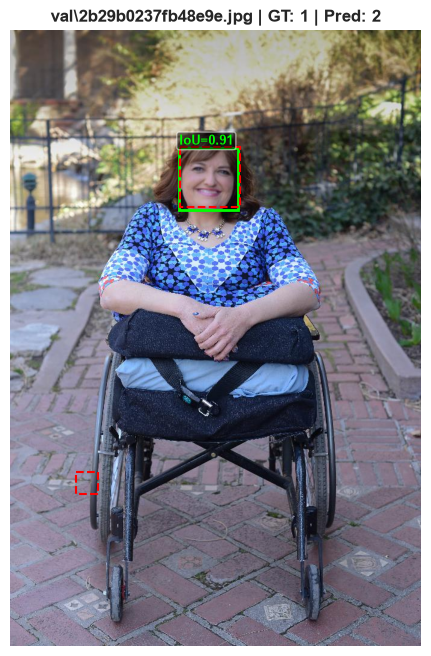


🔴 PIOR CASO (Falsos Positivos / Alucinação):


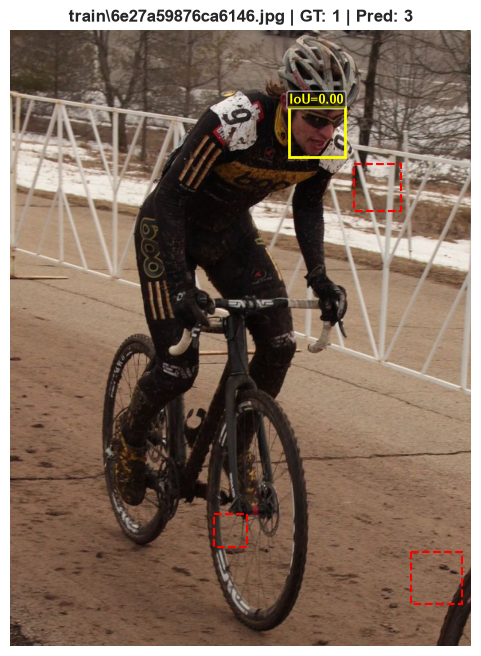

In [43]:
def visualize_predictions(record: dict, images_dir: Path, iou_threshold: float = 0.5):
    """Visualiza as predições do Haar Cascade vs ground truth."""
    img_path = images_dir / record["img_rel_path"]
    
    # Se a imagem não existir como .jpg, tenta .png
    if not img_path.exists():
        img_path = img_path.with_suffix('.png')
        
    img, faces_detected, _, _ = detect_faces_haar(img_path)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    gt_boxes = [(b["x"], b["y"], b["w"], b["h"]) for b in record["boxes"]]
    pred_boxes = [(int(x), int(y), int(w), int(h)) for (x, y, w, h) in faces_detected]

    ious = get_image_scores(pred_boxes, gt_boxes, min_iou=0.0)

    fig, ax = plt.subplots(figsize=(12, 8))
    ax.imshow(img_rgb)

    # Ground truth em verde
    for b, iou in zip(gt_boxes, ious):
        color = "lime" if iou >= iou_threshold else "yellow"
        rect = patches.Rectangle((b[0], b[1]), b[2], b[3],
                                 linewidth=2, edgecolor=color, facecolor="none")
        ax.add_patch(rect)
        ax.text(b[0], b[1] - 5, f"IoU={iou:.2f}", color=color,
                fontsize=9, weight="bold",
                bbox=dict(boxstyle="round,pad=0.2", facecolor="black", alpha=0.5))

    # Predições em vermelho
    for b in pred_boxes:
        rect = patches.Rectangle((b[0], b[1]), b[2], b[3],
                                 linewidth=1.5, edgecolor="red", facecolor="none",
                                 linestyle="--")
        ax.add_patch(rect)

    ax.set_title(f"{record['img_rel_path']} | GT: {len(gt_boxes)} | Pred: {len(pred_boxes)}",
                 fontsize=12, weight="bold")
    ax.axis("off")
    plt.show()


# Mostrar alguns exemplos interessantes
print("\nExemplos de imagens com diferentes desempenhos:\n")

# Melhor caso (alto IoU)
print("🟢 MELHOR CASO:")
best = df_results.loc[df_results["mean_iou"].idxmax()]
best_record = next(r for r in test_records if r["img_rel_path"] == best["img_rel_path"])
visualize_predictions(best_record, images_dir=EXT_IMAGES_DIR)

# Pior caso (baixo IoU) - Garantir que tem pelo menos 1 Ground Truth
print("\n🔴 PIOR CASO (Falsos Positivos / Alucinação):")
worst_candidates = df_results[(df_results["n_gt"] > 0) & (df_results["n_pred"] > 0)]
worst = worst_candidates.loc[worst_candidates["mean_iou"].idxmin()]
worst_record = next(r for r in test_records if r["img_rel_path"] == worst["img_rel_path"])

visualize_predictions(worst_record, images_dir=EXT_IMAGES_DIR)

✅ Standard PR Curve saved at: haar_standard_pr_curve.svg


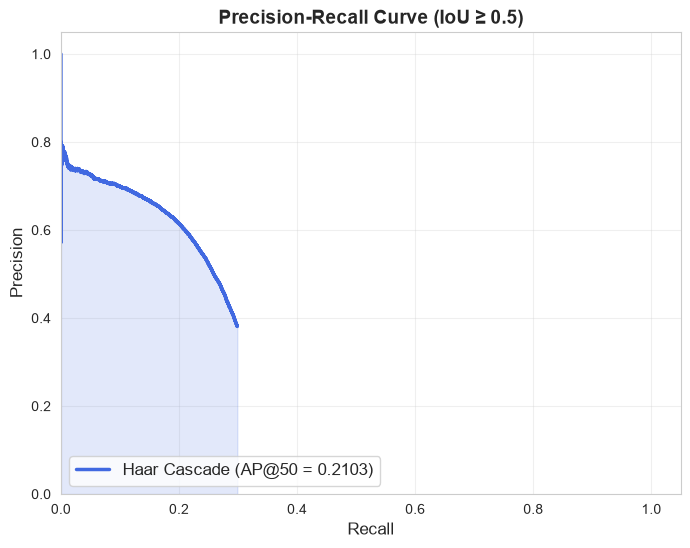

✅ Sensitivity Curve saved at: haar_iou_sensitivity.svg


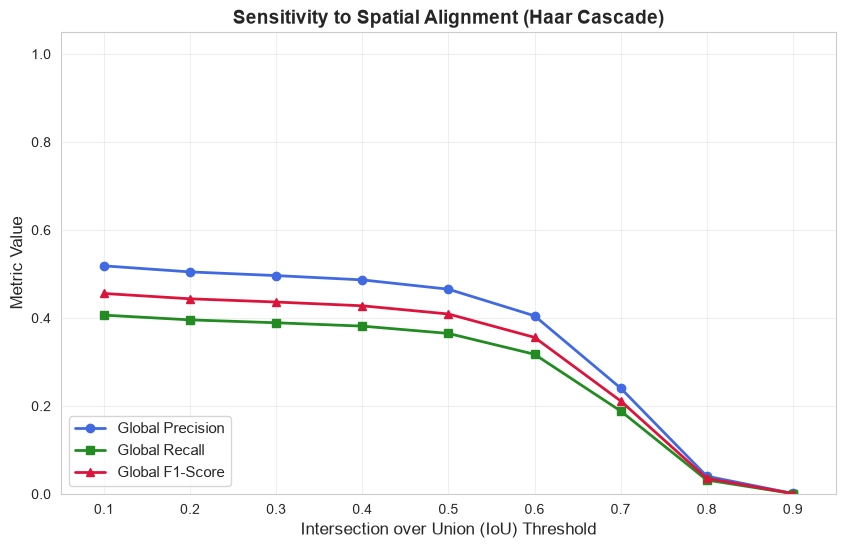

In [41]:
def compute_standard_pr_curve(df_results, iou_threshold=0.5):
    """
    Computes the standard Precision-Recall curve and AP (Average Precision)
    by ranking all detections based on their confidence scores, mimicking standard object detection metrics (e.g., COCO mAP).
    """
    all_detections = []
    total_gt_faces = df_results["n_gt"].sum()
    
    if total_gt_faces == 0:
        return pd.DataFrame(), 0.0
    
    # 1. Gather and flatten all detections across all images
    for _, row in df_results.iterrows():
        # Ensure we only process images that have actual detections
        if not isinstance(row["confidences"], list) or len(row["confidences"]) == 0:
            continue
            
        for conf, iou in zip(row["confidences"], row["matched_ious"]):
            all_detections.append({
                "confidence": conf,
                "is_tp": 1 if iou >= iou_threshold else 0
            })
            
    if not all_detections:
        return pd.DataFrame(), 0.0

    # 2. Sort all detections by confidence in descending order (highest confidence first)
    df_dets = pd.DataFrame(all_detections)
    df_dets = df_dets.sort_values(by="confidence", ascending=False).reset_index(drop=True)
    
    # 3. Calculate cumulative True Positives and False Positives
    df_dets["acc_tp"] = df_dets["is_tp"].cumsum()
    df_dets["acc_fp"] = (~df_dets["is_tp"].astype(bool)).astype(int).cumsum()
    
    # 4. Calculate Precision and Recall at each rank step
    df_dets["precision"] = df_dets["acc_tp"] / (df_dets["acc_tp"] + df_dets["acc_fp"])
    df_dets["recall"] = df_dets["acc_tp"] / total_gt_faces
    
    # 5. Compute Average Precision (AP) using the 11-point interpolation method (Pascal VOC standard)
    ap = 0.0
    for t in np.arange(0.0, 1.1, 0.1):
        p_at_recall = df_dets[df_dets["recall"] >= t]["precision"].max()
        if pd.notna(p_at_recall):
            ap += p_at_recall / 11.0
            
    return df_dets, ap

df_standard_pr, ap_50 = compute_standard_pr_curve(df_results, iou_threshold=0.5)

# ---------------------------------------------------------
# PLOT 1: Standard Precision-Recall Curve (Confidence Sweep)
# ---------------------------------------------------------
plt.figure(figsize=(8, 6))

if not df_standard_pr.empty:
    plt.plot(df_standard_pr["recall"], df_standard_pr["precision"], 
             color='royalblue', linewidth=2.5, label=f'Haar Cascade (AP@50 = {ap_50:.4f})')
    plt.fill_between(df_standard_pr["recall"], df_standard_pr["precision"], color='royalblue', alpha=0.15)
else:
    plt.text(0.5, 0.5, 'No detections found to plot.', horizontalalignment='center')

plt.title("Precision-Recall Curve (IoU \u2265 0.5)", fontsize=14, fontweight="bold")
plt.xlabel("Recall", fontsize=12)
plt.ylabel("Precision", fontsize=12)
plt.xlim([0.0, 1.05])
plt.ylim([0.0, 1.05])
plt.grid(True, alpha=0.3)
plt.legend(loc="lower left", fontsize=12)

# Save the plot
pr_curve_path = Path(OUTPUT_FILE).parent / "haar_standard_pr_curve.svg"
plt.savefig(pr_curve_path, format="svg", bbox_inches="tight")
print(f"✅ Standard PR Curve saved at: {pr_curve_path}")
plt.show()

# ---------------------------------------------------------
# PLOT 2: Sensitivity to Spatial Alignment (IoU Sweep)
# ---------------------------------------------------------
def compute_iou_sensitivity(df_results, iou_thresholds=np.arange(0.1, 1.0, 0.1)):
    """Computes global metrics for different IoU thresholds."""
    sens_results = []
    
    for th in iou_thresholds:
        total_tp = 0
        total_pred = df_results["n_pred"].sum()
        total_gt = df_results["n_gt"].sum()
        
        for _, row in df_results.iterrows():
            if isinstance(row["matched_ious"], list):
                total_tp += sum(1 for iou in row["matched_ious"] if iou >= th)
                
        total_fp = total_pred - total_tp
        total_fn = total_gt - total_tp
        
        precision = total_tp / (total_tp + total_fp) if (total_tp + total_fp) > 0 else 0.0
        recall = total_tp / (total_tp + total_fn) if (total_gt) > 0 else 0.0
        f1 = (2 * precision * recall) / (precision + recall + 1e-9)
        
        sens_results.append({"iou_th": th, "precision": precision, "recall": recall, "f1": f1})
        
    return pd.DataFrame(sens_results)

df_sensitivity = compute_iou_sensitivity(df_results)

plt.figure(figsize=(10, 6))
plt.plot(df_sensitivity["iou_th"], df_sensitivity["precision"], marker='o', color='royalblue', linewidth=2, label='Global Precision')
plt.plot(df_sensitivity["iou_th"], df_sensitivity["recall"], marker='s', color='forestgreen', linewidth=2, label='Global Recall')
plt.plot(df_sensitivity["iou_th"], df_sensitivity["f1"], marker='^', color='crimson', linewidth=2, label='Global F1-Score')

plt.title("Sensitivity to Spatial Alignment (Haar Cascade)", fontsize=14, fontweight="bold")
plt.xlabel("Intersection over Union (IoU) Threshold", fontsize=12)
plt.ylabel("Metric Value", fontsize=12)
plt.xlim([0.05, 0.95])
plt.ylim([0.0, 1.05])
plt.xticks(np.arange(0.1, 1.0, 0.1))
plt.grid(True, alpha=0.3)
plt.legend(loc="lower left", fontsize=11)

# Save the plot
sens_curve_path = Path(OUTPUT_FILE).parent / "haar_iou_sensitivity.svg"
plt.savefig(sens_curve_path, format="svg", bbox_inches="tight")
print(f"✅ Sensitivity Curve saved at: {sens_curve_path}")
plt.show()

## 10. Resumo e Conclusões

In [42]:
print("=" * 70)
print("RESUMO FINAL")
print("=" * 70)
print(f"\n📊 Dataset WIDER FACE:")
print(f"   - Imagens processadas: {metrics['n_images']}")
print(f"   - Total de rostos (GT): {metrics['total_gt']}")
print(f"   - Total de deteções: {metrics['total_pred']}")
print(f"\n🎯 Desempenho Global (IoU ≥ 0.5):")
print(f"   - Precision: {metrics['precision']:.4f}")
print(f"   - Recall:    {metrics['recall']:.4f}")
print(f"   - F1-Score:  {metrics['f1']:.4f}")
print(f"   - IoU médio: {metrics['mean_iou']:.4f}")
print(f"\n⚡ Velocidade:")
print(f"   - Tempo médio de inferência: {metrics['mean_inference_time']*1000:.2f} ms")
# print(f"\n📈 Distribuição por dificuldade:")
# for level in ["Easy", "Medium", "Hard"]:
#     count = len(df_results[df_results["difficulty"] == level])
#     print(f"   - {level:8s}: {count:4d} imagens")

RESUMO FINAL

📊 Dataset WIDER FACE:
   - Imagens processadas: 16733
   - Total de rostos (GT): 51831
   - Total de deteções: 40639

🎯 Desempenho Global (IoU ≥ 0.5):
   - Precision: 0.4656
   - Recall:    0.3650
   - F1-Score:  0.4092
   - IoU médio: 0.3446

⚡ Velocidade:
   - Tempo médio de inferência: 188.73 ms


### Observações Finais

1. **Haar Cascade** é um método clássico, rápido e eficiente em cenários controlados (rostos frontais, boa iluminação).
2. O desempenho degrada significativamente em casos **Hard** (rostos pequenos, oclusões severas, poses extremas).
3. O **IoU médio** é uma boa métrica para avaliar a qualidade do alinhamento das bounding boxes.
4. Para cenários do mundo real, métodos baseados em **deep learning** (MTCNN, YOLO-Face, etc.) tendem a superar o Haar Cascade, especialmente em casos difíceis.

### Próximos Passos Sugeridos

- Comparar com **MTCNN** ou **YOLO-Face**
- Explorar técnicas de **data augmentation** para melhorar a robustez
- Implementar um **ensemble** de detetores
- Avaliar o impacto de diferentes **limiares de IoU** nas métricas finais